In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

#Data 전처리 (방한 외래 관광객 데이터 + 환율 데이터)

In [ ]:
from IPython.core.history import extract_hist_ranges
df = pd.read_csv('/content/방학외래관광객(1995~2025)(2).csv')
Exchage_rate = pd.read_csv('/content/monthly_exchange_rate_98_24(2).csv')

In [ ]:
df = df.rename(columns={
    "기준년월": "Date",
    "관광": "tour",
    "상용": "business",
    "공용": "public",
    "유학연수": "edu",
    "기타": "etc"
})
df['Date'] = pd.to_datetime(df['Date'], format="%Y%m")
Exchage_rate['Date'] = Exchage_rate['Date'].astype(str)
Exchage_rate['Date'] = Exchage_rate['Date'].str.replace(r'\.1$', '.10', regex=True)
Exchage_rate['Date'] = pd.to_datetime(Exchage_rate['Date'], format="%Y.%m")
print(df.head())
print(Exchage_rate.head(12))

        Date    tour  business  public  edu    etc
0 1995-01-01  167307     12740    2180  519  78088
1 1995-02-01  180587     15065    1861  716  74557
2 1995-03-01  204407     15713    1884  451  84965
3 1995-04-01  187153     16008    2595  265  92160
4 1995-05-01  216938     16577    2415  248  98949
         Date Currency  Avg_Rate
0  1998-01-01      USD   1706.80
1  1998-02-01      USD   1623.06
2  1998-03-01      USD   1397.00
3  1998-04-01      USD   1397.00
4  1998-05-01      USD   1394.60
5  1998-06-01      USD   1397.00
6  1998-07-01      USD   1350.00
7  1998-08-01      USD   1300.00
8  1998-09-01      USD   1351.80
9  1998-10-01      USD   1274.80
10 1998-11-01      USD   1313.63
11 1998-12-01      USD   1213.65


In [ ]:
print(df.isnull().sum())
print(Exchage_rate.isnull().sum())

Date        0
tour        0
business    0
public      0
edu         0
etc         0
dtype: int64
Date        0
Currency    0
Avg_Rate    0
dtype: int64


In [ ]:
df = df[df['Date'].dt.year.between(1998, 2024)]
df = df.reset_index(drop=True)

In [ ]:
print(df)
print(Exchage_rate)

          Date     tour  business  public    edu     etc
0   1998-01-01   180627     12251    2503    769   81269
1   1998-02-01   223254     13169    1765   1225   75248
2   1998-03-01   263923     13985    2018    817   87122
3   1998-04-01   235952     12814    2651    485   85240
4   1998-05-01   252713     13455    2480    384   87422
..         ...      ...       ...     ...    ...     ...
283 2024-08-01  1245119     11665    6601  84807  215029
284 2024-09-01  1186832     12179    7028  49835  208426
285 2024-10-01  1363685     12724    6911  18288  198655
286 2024-11-01  1144106     12229    7220  25754  171767
287 2024-12-01  1068024      9814    5972  29175  157878

[288 rows x 6 columns]
          Date Currency  Avg_Rate
0   1998-01-01      USD   1706.80
1   1998-02-01      USD   1623.06
2   1998-03-01      USD   1397.00
3   1998-04-01      USD   1397.00
4   1998-05-01      USD   1394.60
..         ...      ...       ...
283 2024-08-01      USD   1354.15
284 2024-09-01      

In [ ]:
data = df.merge(Exchage_rate[['Date','Avg_Rate']], on='Date', how='left')
data.set_index('Date', inplace=True)
data = np.log(data)
data

,tour,business,public,edu,etc,Avg_Rate
Date,,,,,,
1998-01-01,12.104189,9.413363,7.825245,6.645091,11.305520,7.442376
1998-02-01,12.316065,9.485621,7.475906,7.110696,11.228545,7.392069
1998-03-01,12.483413,9.545741,7.609862,6.705639,11.375065,7.242082
1998-04-01,12.371384,9.458294,7.882692,6.184149,11.353226,7.242082
1998-05-01,12.440010,9.507106,7.816014,5.950643,11.378502,7.240363
...,...,...,...,...,...,...
2024-08-01,14.034742,9.364348,8.794976,11.348133,12.278528,7.210929
2024-09-01,13.986798,9.407468,8.857657,10.816473,12.247339,7.196552
2024-10-01,14.125701,9.451245,8.840870,9.814000,12.199325,7.215975


#SARIMAX(계절성 + 외생변수)

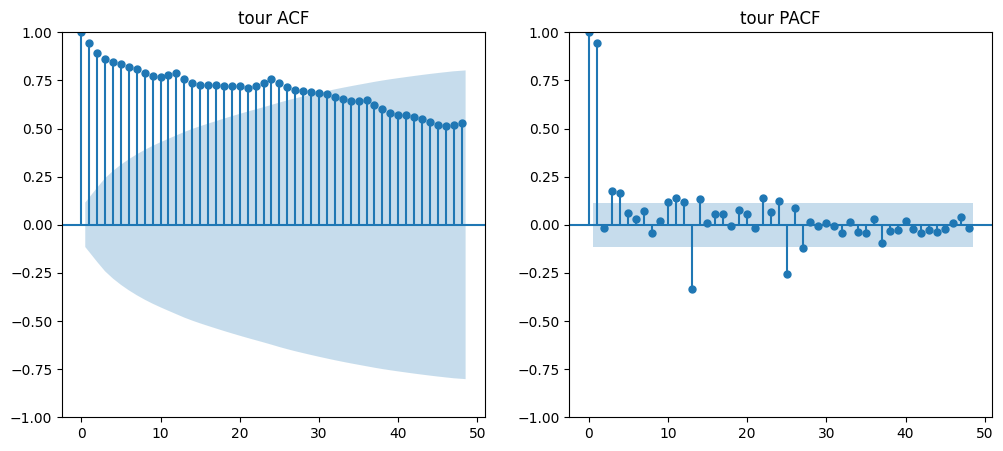

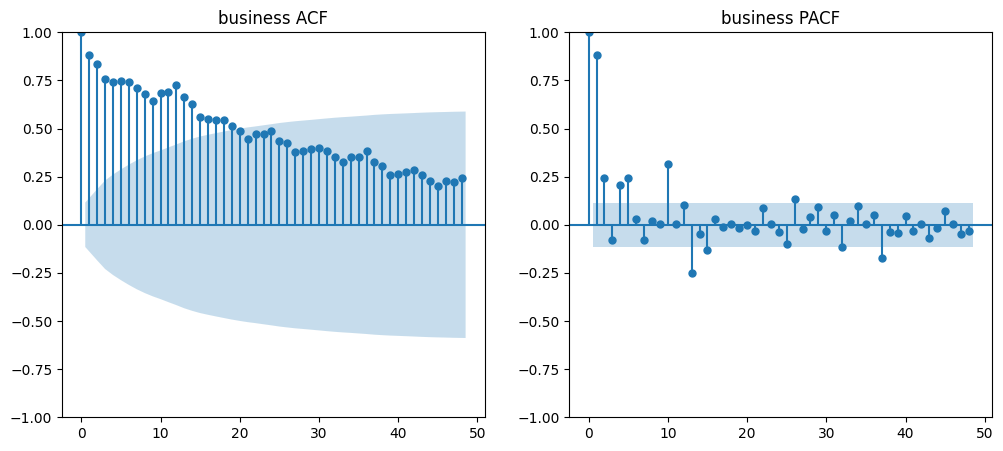

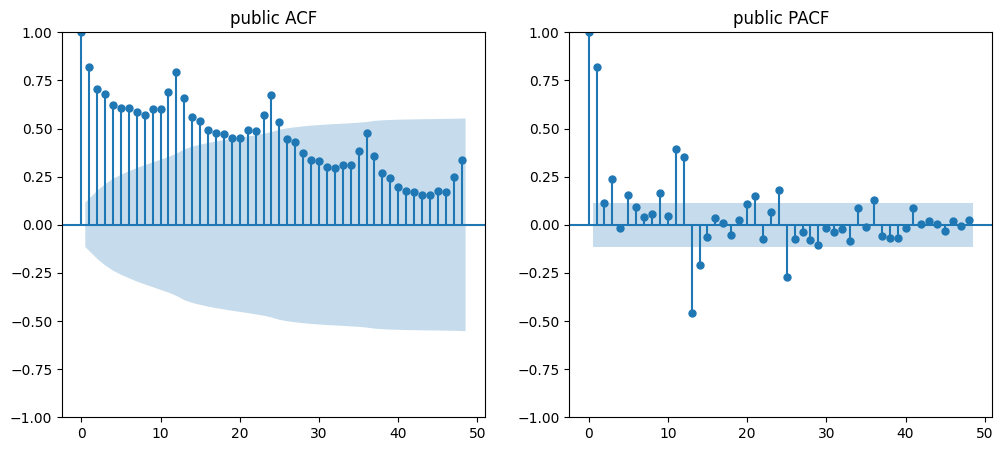

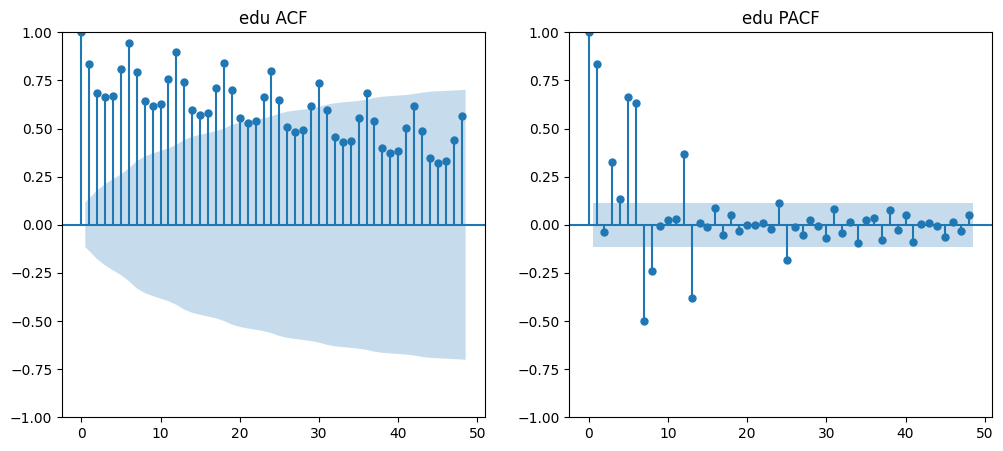

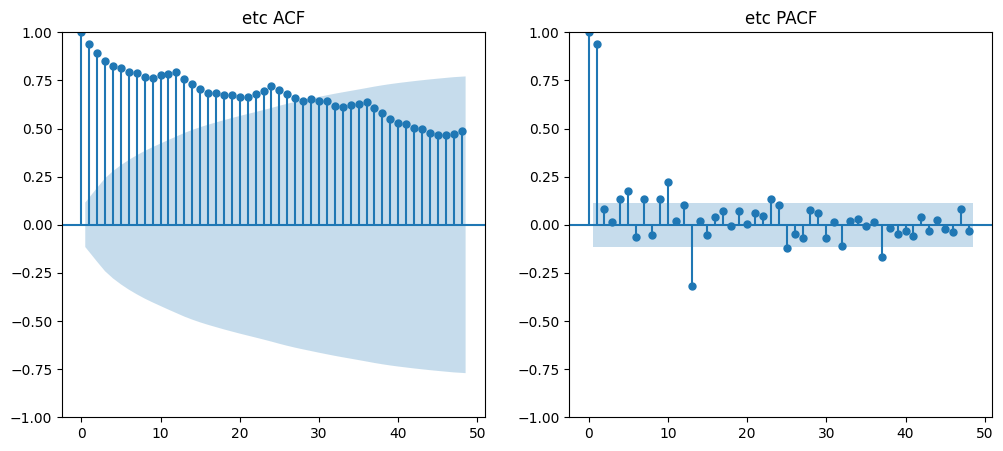

In [ ]:
targets = ['tour', 'business', 'public', 'edu', 'etc']

for target in targets:
    series = data[target]

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plot_acf(series.dropna(), lags=48, ax=plt.gca())
    plt.title(f'{target} ACF')

    plt.subplot(1,2,2)
    plot_pacf(series.dropna(), lags=48, ax=plt.gca())
    plt.title(f'{target} PACF')

    plt.show()

In [ ]:
diff_1 = {}

for target in targets:
    diff_1[target] = data[target].diff()

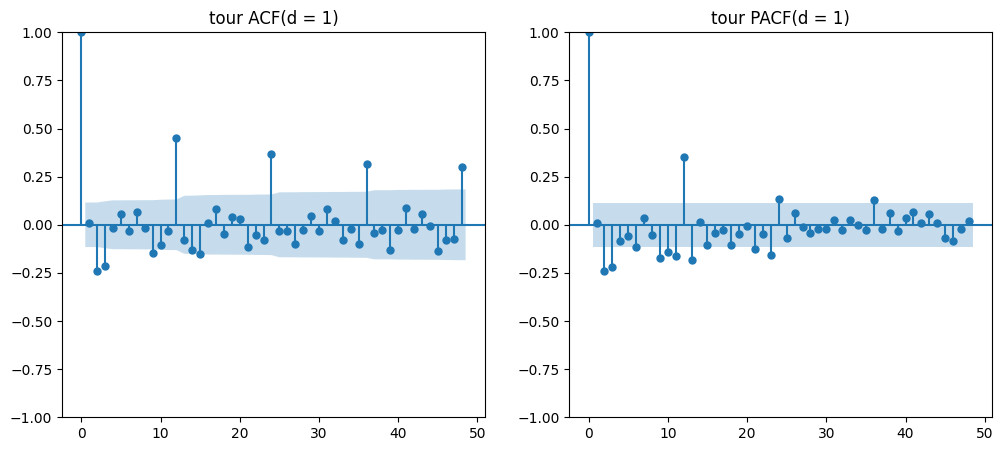

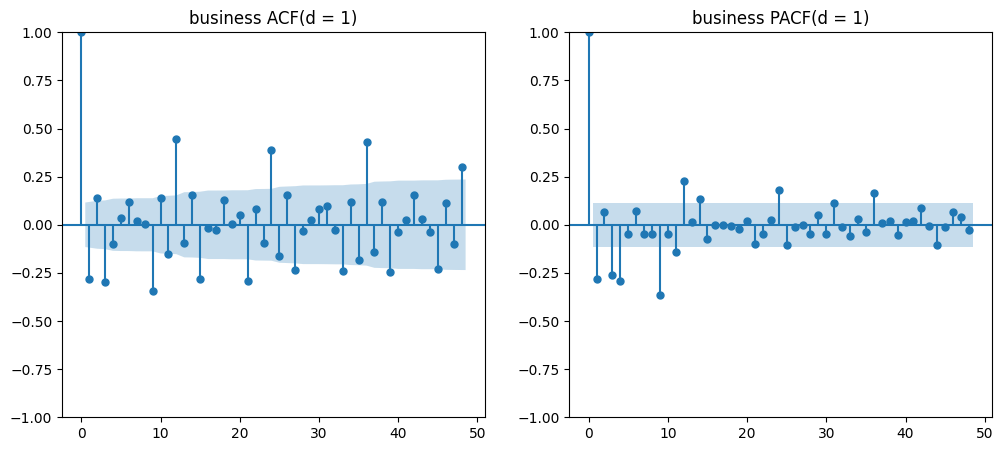

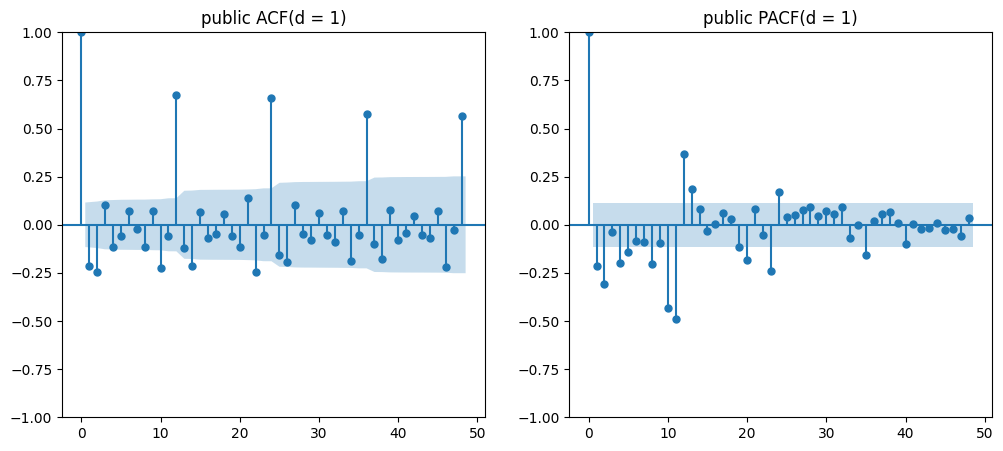

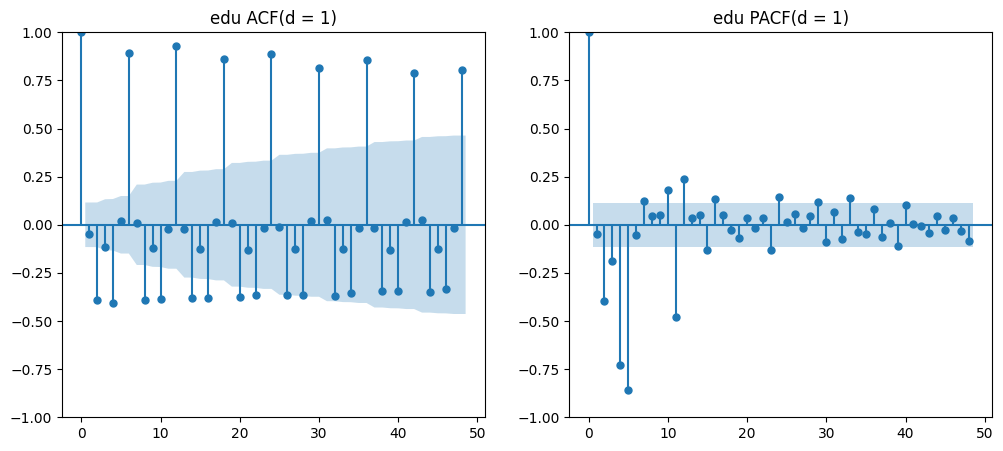

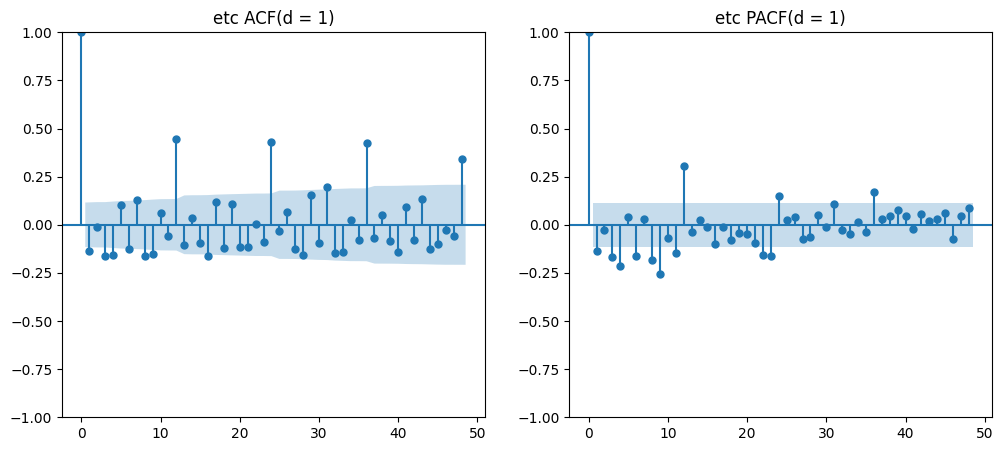

In [ ]:
for target in targets:
    series = diff_1[target]

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plot_acf(series.dropna(), lags=48, ax=plt.gca())
    plt.title(f'{target} ACF(d = 1)')

    plt.subplot(1,2,2)
    plot_pacf(series.dropna(), lags=48, ax=plt.gca())
    plt.title(f'{target} PACF(d = 1)')

    plt.show()

각 모두 1차 차분하였으나 계절성이 모두 띄어서 계절차분도 진행

In [ ]:
diff_12 = {}

for target in targets:
    diff_12[target] = diff_1[target].diff(12)

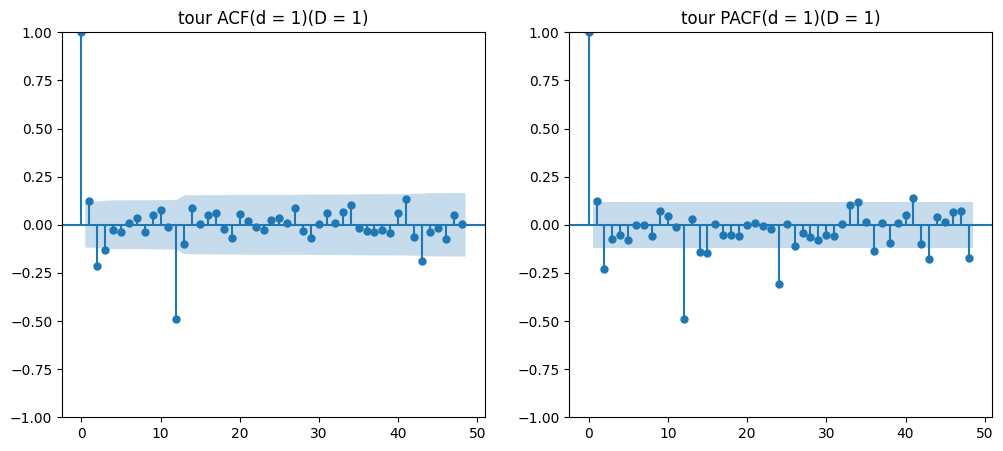

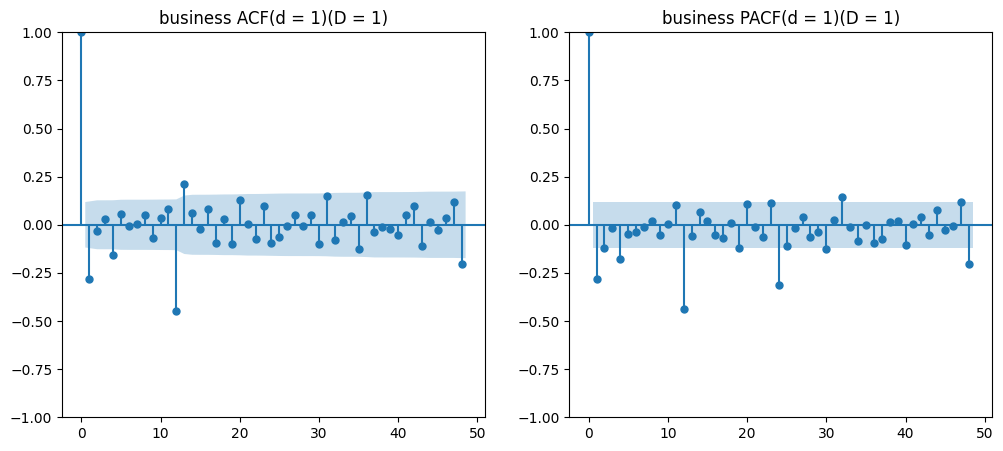

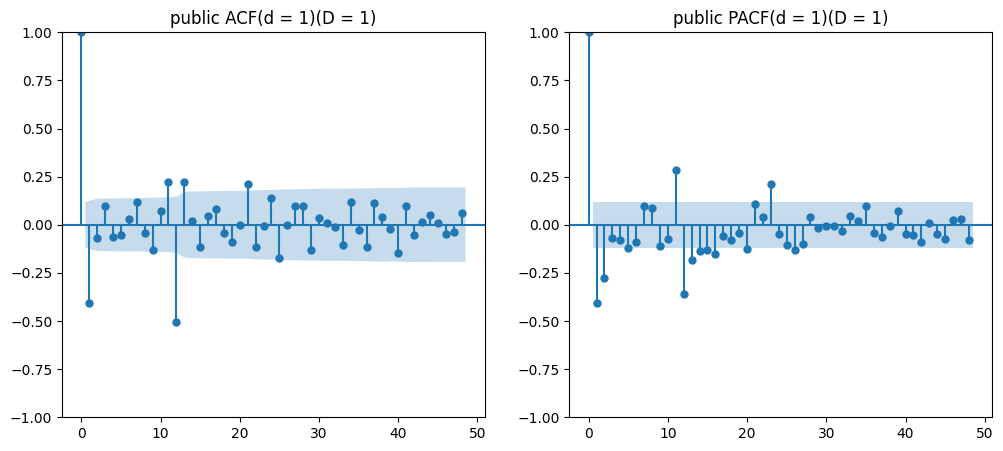

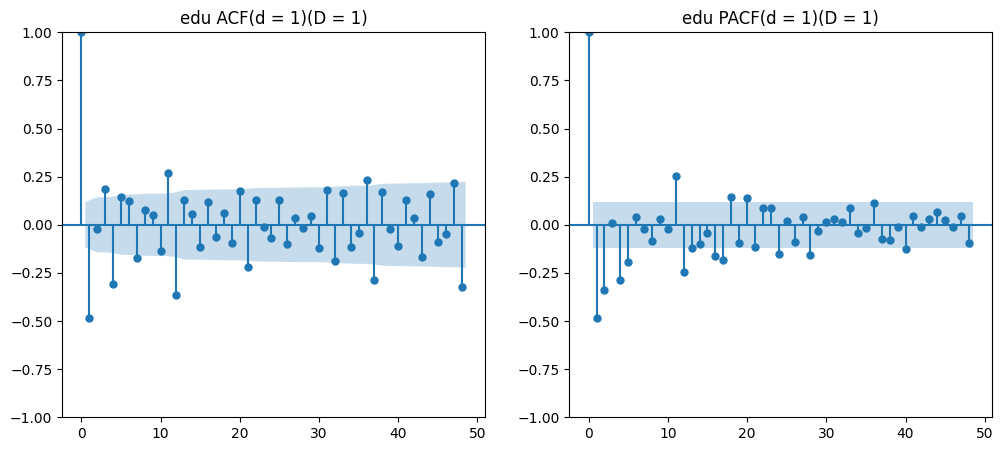

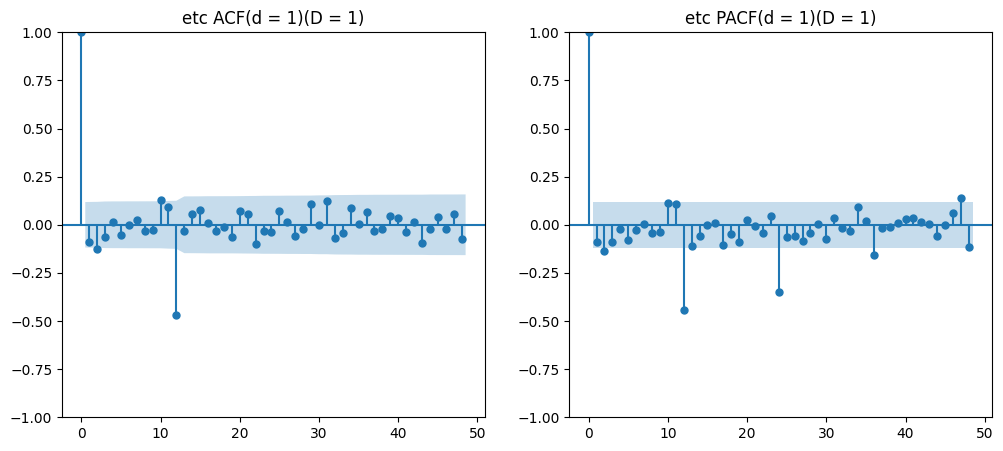

In [ ]:
for target in targets:
    series12 = diff_12[target]

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plot_acf(series12.dropna(), lags=48, ax=plt.gca())
    plt.title(f'{target} ACF(d = 1)(D = 1)')

    plt.subplot(1,2,2)
    plot_pacf(series12.dropna(), lags=48, ax=plt.gca())
    plt.title(f'{target} PACF(d = 1)(D = 1)')

    plt.show()

###1) tour

In [ ]:
# !pip install pmdarima
import pmdarima as pm

In [ ]:
n_test = 24
train_tour = data['tour'].iloc[:-n_test]
train_exog = data[['Avg_Rate']].iloc[:-n_test]

test_tour = data['tour'].iloc[-n_test:]
test_exog = data[['Avg_Rate']].iloc[-n_test:]

print("Train range:", train_tour.index[0], "~", train_tour.index[-1])
print("Test  range:", test_tour.index[0], "~", test_tour.index[-1])
print("Train_exog range:", train_exog.index[0], "~", train_exog.index[-1])
print("Text_exog  range:", test_exog.index[0], "~", test_exog.index[-1])

In [ ]:
print("Last few values of train_tour:")
display(train_tour.tail())
print("\nFirst few values of test_tour:")
display(test_tour.head())

Last few values of train_tour:


,tour
Date,
2019-08-01,14.040064
2019-09-01,13.979686
2019-10-01,14.154534
2019-11-01,14.026179
2019-12-01,14.036521



First few values of test_tour:


,tour
Date,
2023-01-01,12.653470
2023-02-01,12.673254
2023-03-01,13.349787
2023-04-01,13.510167
2023-05-01,13.447036


In [ ]:
covid_start = '2020-01-01'
covid_end = '2022-12-01'
train_tour_clean = train_tour[~((train_tour.index >= covid_start) & (train_tour.index <= covid_end))]
train_exog_clean = train_exog.loc[train_tour_clean.index]

In [ ]:
auto_model = pm.auto_arima(
    train_tour,
    exog=train_exog,
    start_p=1, start_q=1,
    max_p=3, max_q=3,
    m=12,
    seasonal=True,
    d=1, D=1,
    stepwise=True,
    suppress_warnings=True,
    trace=True
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=-443.972, Time=3.71 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=-295.739, Time=0.06 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=-370.354, Time=0.26 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=-442.101, Time=0.92 sec
 ARIMA(1,1,1)(0,1,1)[12]             : AIC=-445.374, Time=1.49 sec
 ARIMA(1,1,1)(0,1,0)[12]             : AIC=-314.342, Time=0.17 sec
 ARIMA(1,1,1)(0,1,2)[12]             : AIC=-444.049, Time=8.13 sec
 ARIMA(1,1,1)(1,1,0)[12]             : AIC=-384.477, Time=2.05 sec
 ARIMA(1,1,1)(1,1,2)[12]             : AIC=inf, Time=6.81 sec
 ARIMA(1,1,0)(0,1,1)[12]             : AIC=-433.491, Time=0.81 sec
 ARIMA(2,1,1)(0,1,1)[12]             : AIC=-462.054, Time=2.81 sec
 ARIMA(2,1,1)(0,1,0)[12]             : AIC=-325.428, Time=0.39 sec
 ARIMA(2,1,1)(1,1,1)[12]             : AIC=-460.971, Time=4.65 sec
 ARIMA(2,1,1)(0,1,2)[12]             : AIC=-461.040, Time=6.28 sec
 ARIMA(2,1,1)(1,1,0)[12]

In [ ]:
order = (1, 1, 1)
seasonal_order = (1, 1, 1, 12)

model = SARIMAX(
    train_tour,
    order=order,
    exog=train_exog,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit()
print(results.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                               tour   No. Observations:                  264
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 212.630
Date:                            Fri, 19 Dec 2025   AIC                           -413.260
Time:                                    22:02:35   BIC                           -392.451
Sample:                                01-01-1998   HQIC                          -404.872
                                     - 12-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Avg_Rate       0.1923      0.309      0.623      0.533      -0.413       0.797
ar.L1         -0.3433      0.140   

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                               tour   No. Observations:                  264
Model:             SARIMAX(3, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 223.273
Date:                            Fri, 19 Dec 2025   AIC                           -430.546
Time:                                    22:44:21   BIC                           -402.802
Sample:                                01-01-1998   HQIC                          -419.363
                                     - 12-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Avg_Rate       0.1504      0.248      0.606      0.544      -0.336       0.637
covid               0        nan   

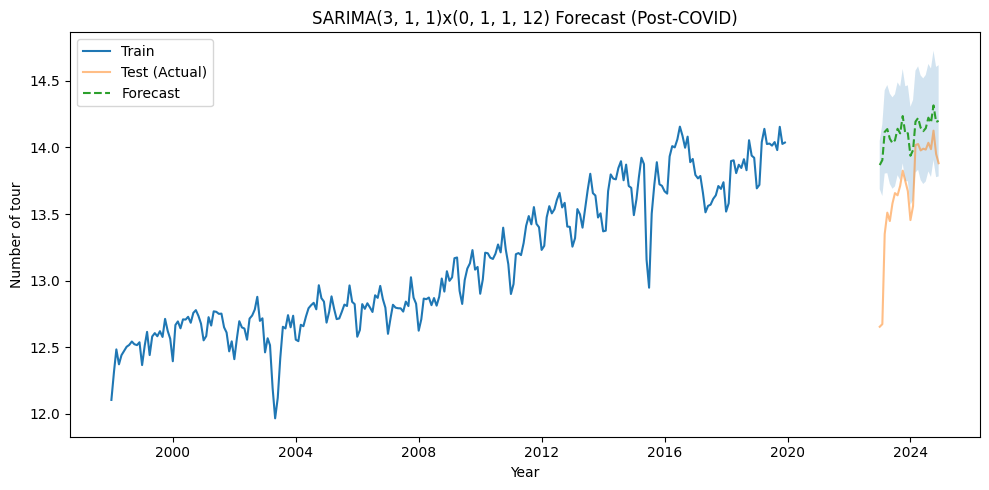

MAE  : 0.43
RMSE : 0.52
SMAPE : 3.12%


In [ ]:
covid_start = '2020-02-01'
covid_end = '2022-12-01'

train_exog['covid'] = ((train_tour.index >= covid_start) & (train_tour.index <= covid_end)).astype(int)
test_exog['covid'] = ((test_tour.index >= covid_start) & (test_tour.index <= covid_end)).astype(int)

# ----------------------------
# 3. SARIMAX 모델 학습
# ----------------------------
order = (3, 1, 1)
seasonal_order = (0, 1, 1, 12)

best_model = SARIMAX(
    train_tour,
    order=order,
    seasonal_order=seasonal_order,
    exog=train_exog,
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = best_model.fit()
print(results.summary())

# ----------------------------
# 4. 예측
# ----------------------------
forecast = results.get_forecast(steps=len(test_tour), exog=test_exog)
pred_mean = forecast.predicted_mean
pred_ci = forecast.conf_int()

# 인덱스를 test_tour.index와 동일하게 설정
pred_mean.index = test_tour.index
pred_ci.index = test_tour.index

# ----------------------------
# 5. 코로나 이후 구간만 선택
# ----------------------------
covid_end = '2022-12-01'
forecast_index = test_tour[test_tour.index > covid_end].index

y_true = test_tour.loc[forecast_index]
y_pred = pred_mean.loc[forecast_index]
pred_ci = pred_ci.loc[forecast_index]

# ----------------------------
# 6. 시각화
# ----------------------------
plt.figure(figsize=(10, 5))
plt.plot(train_tour_clean.index, train_tour_clean, label='Train')
plt.plot(test_tour.index, test_tour, label='Test (Actual)', alpha=0.5)
plt.plot(pred_mean.index, pred_mean, label='Forecast', linestyle='--')

plt.fill_between(
    pred_ci.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    alpha=0.2
)

plt.title(f"SARIMA{order}x{seasonal_order} Forecast (Post-COVID)")
plt.xlabel("Year")
plt.ylabel("Number of tour")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------
# 7. 평가 지표 계산
# ----------------------------
mae = mean_absolute_error(y_true, y_pred)
rmse = mean_squared_error(y_true, y_pred) ** 0.5

y_true_np = y_true.to_numpy()
y_pred_np = y_pred.to_numpy()
epsilon = 1e-10
smape = 100 * np.mean(2 * np.abs(y_true_np - y_pred_np) / (np.abs(y_true_np) + np.abs(y_pred_np) + epsilon))

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"SMAPE : {smape:.2f}%")

### 2) business

In [ ]:
n_test = 24
train_business = data['business'].iloc[:-n_test]
train_exog = data[['Avg_Rate']].iloc[:-n_test]

test_business = data['business'].iloc[-n_test:]
test_exog = data[['Avg_Rate']].iloc[-n_test:]

print("Train range:", train_business.index[0], "~", train_business.index[-1])
print("Test  range:", test_business.index[0], "~", test_business.index[-1])
print("Train_exog range:", train_exog.index[0], "~", train_exog.index[-1])
print("Text_exog  range:", test_exog.index[0], "~", test_exog.index[-1])

Train range: 1998-01-01 00:00:00 ~ 2019-12-01 00:00:00
Test  range: 2023-01-01 00:00:00 ~ 2024-12-01 00:00:00
Train_exog range: 1998-01-01 00:00:00 ~ 2019-12-01 00:00:00
Text_exog  range: 2023-01-01 00:00:00 ~ 2024-12-01 00:00:00


In [ ]:
print("Last few values of train_business:")
display(train_business.tail())
print("\nFirst few values of test_business:")
display(test_business.head())

Last few values of train_business:


,business
Date,
2019-08-01,9.587063
2019-09-01,9.721246
2019-10-01,9.684709
2019-11-01,9.682092
2019-12-01,9.494541



First few values of test_business:


,business
Date,
2023-01-01,8.941807
2023-02-01,8.906935
2023-03-01,9.263217
2023-04-01,9.204825
2023-05-01,9.351666


In [ ]:
covid_start = '2020-01-01'
covid_end = '2022-12-01'
train_business_clean = train_business[~((train_business.index >= covid_start) & (train_business.index <= covid_end))]
train_exog_clean = train_exog.loc[train_business_clean.index]

In [ ]:
auto_model = pm.auto_arima(
    train_business_clean,
    exog=train_exog_clean,
    start_p=1, start_q=1,
    max_p=3, max_q=3,
    m=12,
    seasonal=True,
    d=1, D=1,
    stepwise=True,
    suppress_warnings=True,
    trace=True
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=inf, Time=4.07 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=-291.357, Time=0.11 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=-356.113, Time=0.32 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=inf, Time=1.04 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=-312.189, Time=0.11 sec
 ARIMA(1,1,0)(2,1,0)[12]             : AIC=-391.397, Time=0.95 sec
 ARIMA(1,1,0)(2,1,1)[12]             : AIC=inf, Time=5.61 sec
 ARIMA(1,1,0)(1,1,1)[12]             : AIC=inf, Time=2.07 sec
 ARIMA(0,1,0)(2,1,0)[12]             : AIC=-376.253, Time=0.62 sec
 ARIMA(2,1,0)(2,1,0)[12]             : AIC=-389.400, Time=1.38 sec
 ARIMA(1,1,1)(2,1,0)[12]             : AIC=-389.346, Time=1.06 sec
 ARIMA(0,1,1)(2,1,0)[12]             : AIC=-391.367, Time=0.95 sec
 ARIMA(2,1,1)(2,1,0)[12]             : AIC=-399.023, Time=3.34 sec
 ARIMA(2,1,1)(1,1,0)[12]             : AIC=-367.444, Time=2.42 sec
 ARIMA(2,1,1)(2,1,1)[12]             : 

In [ ]:
order = (1, 1, 1)
seasonal_order = (1, 1, 1, 12)

model = SARIMAX(
    train_business_clean,
    order=order,
    exog=train_exog_clean,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit()
print(results.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                           business   No. Observations:                  264
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 200.780
Date:                            Fri, 19 Dec 2025   AIC                           -389.560
Time:                                    22:42:29   BIC                           -368.752
Sample:                                01-01-1998   HQIC                          -381.173
                                     - 12-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Avg_Rate       0.0508      0.344      0.148      0.883      -0.623       0.725
ar.L1         -0.4639      0.125   

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                                      SARIMAX Results                                      
Dep. Variable:                            business   No. Observations:                  264
Model:             SARIMAX(3, 1, 1)x(2, 1, [], 12)   Log Likelihood                 179.932
Date:                             Fri, 19 Dec 2025   AIC                           -343.863
Time:                                     22:43:59   BIC                           -316.570
Sample:                                 01-01-1998   HQIC                          -332.846
                                      - 12-01-2019                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Avg_Rate      -0.2854      0.300     -0.952      0.341      -0.873       0.302
ar.L1          0.5770      

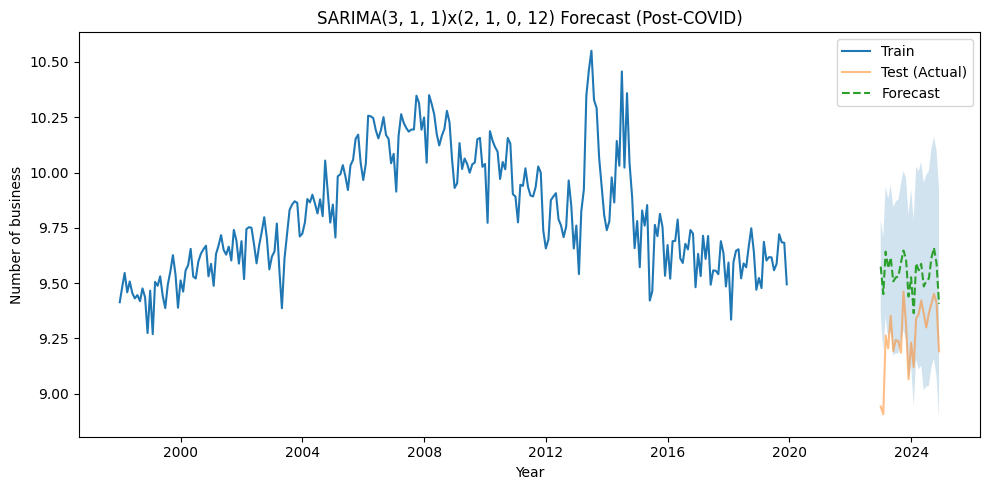

MAE  : 0.28
RMSE : 0.31
SMAPE : 3.01%


In [ ]:


# ----------------------------
# 3. SARIMAX 모델 학습
# ----------------------------
order = (3, 1, 1)
seasonal_order = (2, 1, 0, 12)

best_model = SARIMAX(
    train_business_clean,
    order=order,
    seasonal_order=seasonal_order,
    exog=train_exog_clean,
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = best_model.fit()
print(results.summary())

# ----------------------------
# 4. 예측
# ----------------------------
forecast = results.get_forecast(steps=len(test_business), exog=test_exog)
pred_mean = forecast.predicted_mean
pred_ci = forecast.conf_int()


pred_mean.index = test_business.index
pred_ci.index = test_business.index

# ----------------------------
# 5. 코로나 이후 구간만 선택
# ----------------------------
covid_end = '2022-12-01'
forecast_index = test_business[test_business.index > covid_end].index

y_true = test_business.loc[forecast_index]
y_pred = pred_mean.loc[forecast_index]
pred_ci = pred_ci.loc[forecast_index]

# ----------------------------
# 6. 시각화
# ----------------------------
plt.figure(figsize=(10, 5))
plt.plot(train_business_clean.index, train_business_clean, label='Train')
plt.plot(test_business.index, test_business, label='Test (Actual)', alpha=0.5)
plt.plot(pred_mean.index, pred_mean, label='Forecast', linestyle='--')

plt.fill_between(
    pred_ci.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    alpha=0.2
)

plt.title(f"SARIMA{order}x{seasonal_order} Forecast (Post-COVID)")
plt.xlabel("Year")
plt.ylabel("Number of business")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------
# 7. 평가 지표 계산
# ----------------------------
mae = mean_absolute_error(y_true, y_pred)
rmse = mean_squared_error(y_true, y_pred) ** 0.5

y_true_np = y_true.to_numpy()
y_pred_np = y_pred.to_numpy()
epsilon = 1e-10
smape = 100 * np.mean(2 * np.abs(y_true_np - y_pred_np) / (np.abs(y_true_np) + np.abs(y_pred_np) + epsilon))

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"SMAPE : {smape:.2f}%")

###3)public

In [ ]:
n_test = 24
train_public = data['public'].iloc[:-n_test]
train_exog = data[['Avg_Rate']].iloc[:-n_test]

test_public = data['public'].iloc[-n_test:]
test_exog = data[['Avg_Rate']].iloc[-n_test:]

print("Train range:", train_public.index[0], "~", train_public.index[-1])
print("Test  range:", test_public.index[0], "~", test_public.index[-1])
print("Train_exog range:", train_exog.index[0], "~", train_exog.index[-1])
print("Text_exog  range:", test_exog.index[0], "~", test_exog.index[-1])

Train range: 1998-01-01 00:00:00 ~ 2019-12-01 00:00:00
Test  range: 2023-01-01 00:00:00 ~ 2024-12-01 00:00:00
Train_exog range: 1998-01-01 00:00:00 ~ 2019-12-01 00:00:00
Text_exog  range: 2023-01-01 00:00:00 ~ 2024-12-01 00:00:00


In [ ]:
print("Last few values of test_public:")
display(train_public.tail())
print("\nFirst few values of test_public:")
display(test_public.head())

Last few values of test_public:


,public
Date,
2019-08-01,8.762177
2019-09-01,8.839711
2019-10-01,8.845633
2019-11-01,8.869961
2019-12-01,8.753371



First few values of test_public:


,public
Date,
2023-01-01,8.329658
2023-02-01,8.059908
2023-03-01,8.459352
2023-04-01,8.631057
2023-05-01,8.726157


In [ ]:
covid_start = '2020-01-01'
covid_end = '2022-12-01'
train_public_clean = train_public[~((train_public.index >= covid_start) & (train_public.index <= covid_end))]
train_exog_clean = train_exog.loc[train_public_clean.index]

In [ ]:
auto_model = pm.auto_arima(
    train_public_clean,
    exog=train_exog_clean,
    start_p=1, start_q=1,
    max_p=3, max_q=3,
    m=12,
    seasonal=True,
    d=1, D=1,
    stepwise=True,
    suppress_warnings=True,
    trace=True
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=-336.251, Time=1.93 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=-175.747, Time=0.12 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=-284.886, Time=0.82 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=-335.904, Time=1.37 sec
 ARIMA(1,1,1)(0,1,1)[12]             : AIC=-337.293, Time=3.09 sec
 ARIMA(1,1,1)(0,1,0)[12]             : AIC=-238.843, Time=0.58 sec
 ARIMA(1,1,1)(0,1,2)[12]             : AIC=-336.048, Time=6.67 sec
 ARIMA(1,1,1)(1,1,0)[12]             : AIC=-316.192, Time=1.84 sec
 ARIMA(1,1,1)(1,1,2)[12]             : AIC=-336.844, Time=8.48 sec
 ARIMA(1,1,0)(0,1,1)[12]             : AIC=-307.721, Time=2.72 sec
 ARIMA(2,1,1)(0,1,1)[12]             : AIC=-335.305, Time=5.22 sec
 ARIMA(1,1,2)(0,1,1)[12]             : AIC=-337.680, Time=6.13 sec
 ARIMA(1,1,2)(0,1,0)[12]             : AIC=-248.612, Time=1.22 sec
 ARIMA(1,1,2)(1,1,1)[12]             : AIC=-336.378, Time=2.14 sec
 ARIMA(1,1,2)(0,1,2

In [ ]:
order = (1, 1, 1)
seasonal_order = (1, 1, 1, 12)

model = SARIMAX(
    train_public_clean,
    order=order,
    exog=train_exog_clean,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit()
print(results.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                             public   No. Observations:                  264
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 159.260
Date:                            Fri, 19 Dec 2025   AIC                           -306.519
Time:                                    22:38:22   BIC                           -285.711
Sample:                                01-01-1998   HQIC                          -298.132
                                     - 12-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Avg_Rate      -0.1054      0.248     -0.426      0.670      -0.591       0.380
ar.L1          0.1845      0.102   

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                      SARIMAX Results                                       
Dep. Variable:                               public   No. Observations:                  264
Model:             SARIMAX(1, 1, 2)x(0, 1, [1], 12)   Log Likelihood                 159.949
Date:                              Fri, 19 Dec 2025   AIC                           -307.899
Time:                                      22:59:17   BIC                           -287.116
Sample:                                  01-01-1998   HQIC                          -299.521
                                       - 12-01-2019                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Avg_Rate      -0.1251      0.248     -0.504      0.614      -0.611       0.361
ar.L1         -0.80

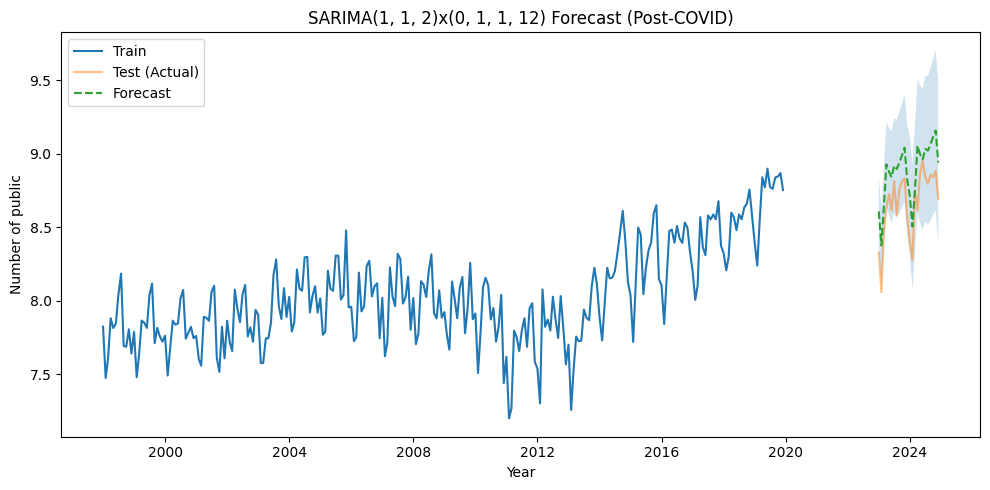

MAE  : 0.22
RMSE : 0.24
SMAPE : 2.49%


In [ ]:


# ----------------------------
# 3. SARIMAX 모델 학습
# ----------------------------
order = (1, 1, 2)
seasonal_order = (0, 1, 1, 12)

best_model = SARIMAX(
    train_public_clean,
    order=order,
    seasonal_order=seasonal_order,
    exog=train_exog_clean,
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = best_model.fit()
print(results.summary())

# ----------------------------
# 4. 예측
# ----------------------------
forecast = results.get_forecast(steps=len(test_public), exog=test_exog)
pred_mean = forecast.predicted_mean
pred_ci = forecast.conf_int()


pred_mean.index = test_public.index
pred_ci.index = test_public.index

# ----------------------------
# 5. 코로나 이후 구간만 선택
# ----------------------------
covid_end = '2022-12-01'
forecast_index = test_public[test_public.index > covid_end].index

y_true = test_public.loc[forecast_index]
y_pred = pred_mean.loc[forecast_index]
pred_ci = pred_ci.loc[forecast_index]

# ----------------------------
# 6. 시각화
# ----------------------------
plt.figure(figsize=(10, 5))
plt.plot(train_public_clean.index, train_public_clean, label='Train')
plt.plot(test_public.index, test_public, label='Test (Actual)', alpha=0.5)
plt.plot(pred_mean.index, pred_mean, label='Forecast', linestyle='--')

plt.fill_between(
    pred_ci.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    alpha=0.2
)

plt.title(f"SARIMA{order}x{seasonal_order} Forecast (Post-COVID)")
plt.xlabel("Year")
plt.ylabel("Number of public")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------
# 7. 평가 지표 계산
# ----------------------------
mae = mean_absolute_error(y_true, y_pred)
rmse = mean_squared_error(y_true, y_pred) ** 0.5

y_true_np = y_true.to_numpy()
y_pred_np = y_pred.to_numpy()
epsilon = 1e-10

smape = 100 * np.mean(2 * np.abs(y_true_np - y_pred_np) / (np.abs(y_true_np) + np.abs(y_pred_np) + epsilon))

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"SMAPE : {smape:.2f}%")

### 4) edu

In [ ]:
n_test = 24
train_edu = data['edu'].iloc[:-n_test]
train_exog = data[['Avg_Rate']].iloc[:-n_test]

test_edu = data['edu'].iloc[-n_test:]
test_exog = data[['Avg_Rate']].iloc[-n_test:]

In [ ]:
print("Last few values of train_edu:")
display(train_edu.tail())
print("\nFirst few values of test_edu:")
display(test_edu.head())

Last few values of train_edu:


,edu
Date,
2019-08-01,11.172236
2019-09-01,10.577630
2019-10-01,9.765030
2019-11-01,9.978966
2019-12-01,10.022869



First few values of test_edu:


,edu
Date,
2023-01-01,9.523251
2023-02-01,10.880139
2023-03-01,10.333418
2023-04-01,8.773539
2023-05-01,9.633318


In [ ]:
covid_start = '2020-01-01'
covid_end = '2022-12-01'
train_edu_clean = train_edu[~((train_edu.index >= covid_start) & (train_public.index <= covid_end))]
train_exog_clean = train_exog.loc[train_edu_clean.index]

In [ ]:
auto_model = pm.auto_arima(
    train_edu_clean,
    exog=train_exog_clean,
    start_p=1, start_q=1,
    max_p=3, max_q=3,
    m=12,
    seasonal=True,
    d=1, D=1,
    stepwise=True,
    suppress_warnings=True,
    trace=True
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=-154.082, Time=1.08 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=11.064, Time=0.17 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=-87.105, Time=0.42 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=-157.036, Time=0.82 sec
 ARIMA(0,1,1)(0,1,0)[12]             : AIC=-124.172, Time=0.22 sec
 ARIMA(0,1,1)(1,1,1)[12]             : AIC=-155.727, Time=2.06 sec
 ARIMA(0,1,1)(0,1,2)[12]             : AIC=-155.973, Time=1.84 sec
 ARIMA(0,1,1)(1,1,0)[12]             : AIC=-154.670, Time=0.33 sec
 ARIMA(0,1,1)(1,1,2)[12]             : AIC=-154.380, Time=5.63 sec
 ARIMA(0,1,0)(0,1,1)[12]             : AIC=-28.071, Time=0.42 sec
 ARIMA(1,1,1)(0,1,1)[12]             : AIC=-155.303, Time=2.26 sec
 ARIMA(0,1,2)(0,1,1)[12]             : AIC=-155.372, Time=0.62 sec
 ARIMA(1,1,0)(0,1,1)[12]             : AIC=-89.225, Time=0.38 sec
 ARIMA(1,1,2)(0,1,1)[12]             : AIC=-156.327, Time=3.67 sec
 ARIMA(0,1,1)(0,1,1)[12]

In [ ]:
order = (1, 1, 1)
seasonal_order = (1, 1, 1, 12)

model = SARIMAX(
    train_edu_clean,
    order=order,
    exog=train_exog_clean,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit()
print(results.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                                edu   No. Observations:                  264
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                  78.012
Date:                            Fri, 19 Dec 2025   AIC                           -144.025
Time:                                    22:55:18   BIC                           -123.216
Sample:                                01-01-1998   HQIC                          -135.637
                                     - 12-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Avg_Rate      -0.1026      0.165     -0.623      0.533      -0.425       0.220
ar.L1         -0.0465      0.078   

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                                etc   No. Observations:                  264
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 259.100
Date:                            Fri, 19 Dec 2025   AIC                           -510.201
Time:                                    23:12:04   BIC                           -496.328
Sample:                                01-01-1998   HQIC                          -504.609
                                     - 12-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Avg_Rate       0.2135      0.196      1.089      0.276      -0.171       0.598
ma.L1         -0.1382      0.051   

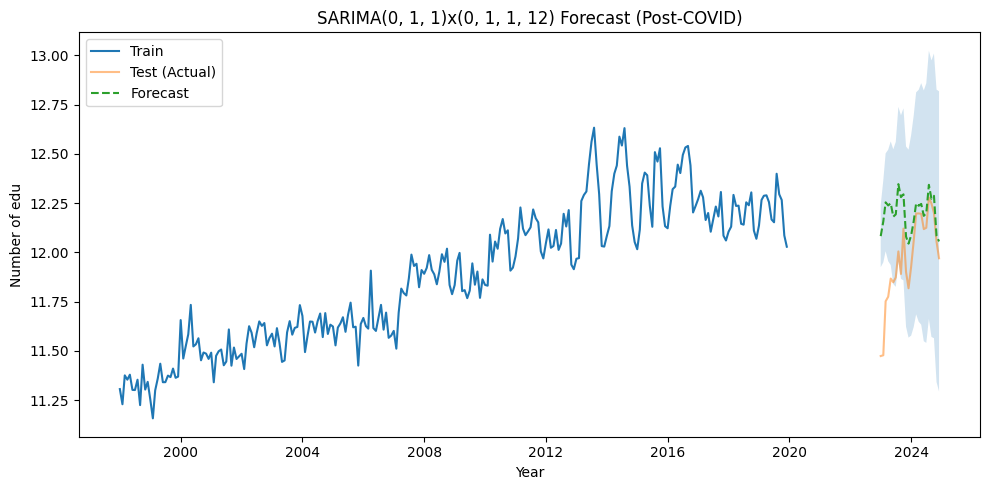

MAE  : 0.23
RMSE : 0.30
SMAPE : 1.89%


In [ ]:
# ----------------------------
# 3. SARIMAX 모델 학습
# ----------------------------
order = (0, 1, 1)
seasonal_order = (0, 1, 1, 12)

best_model = SARIMAX(
    train_edu_clean,
    order=order,
    seasonal_order=seasonal_order,
    exog=train_exog_clean,
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = best_model.fit()
print(results.summary())

# ----------------------------
# 4. 예측
# ----------------------------
forecast = results.get_forecast(steps=len(test_edu), exog=test_exog)
pred_mean = forecast.predicted_mean
pred_ci = forecast.conf_int()


pred_mean.index = test_edu.index
pred_ci.index = test_edu.index

# ----------------------------
# 5. 코로나 이후 구간만 선택
# ----------------------------
covid_end = '2022-12-01'
forecast_index = test_edu[test_edu.index > covid_end].index

y_true = test_edu.loc[forecast_index]
y_pred = pred_mean.loc[forecast_index]
pred_ci = pred_ci.loc[forecast_index]

# ----------------------------
# 6. 시각화
# ----------------------------
plt.figure(figsize=(10, 5))
plt.plot(train_edu_clean.index, train_edu_clean, label='Train')
plt.plot(test_edu.index, test_edu, label='Test (Actual)', alpha=0.5)
plt.plot(pred_mean.index, pred_mean, label='Forecast', linestyle='--')

plt.fill_between(
    pred_ci.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    alpha=0.2
)

plt.title(f"SARIMA{order}x{seasonal_order} Forecast (Post-COVID)")
plt.xlabel("Year")
plt.ylabel("Number of edu")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------
# 7. 평가 지표 계산
# ----------------------------
mae = mean_absolute_error(y_true, y_pred)
rmse = mean_squared_error(y_true, y_pred) ** 0.5

y_true_np = y_true.to_numpy()
y_pred_np = y_pred.to_numpy()
epsilon = 1e-10

smape = 100 * np.mean(2 * np.abs(y_true_np - y_pred_np) / (np.abs(y_true_np) + np.abs(y_pred_np) + epsilon))

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"SMAPE : {smape:.2f}%")

###5)etc

In [ ]:
n_test = 24
train_etc = data['etc'].iloc[:-n_test]
train_exog = data[['Avg_Rate']].iloc[:-n_test]

test_etc = data['etc'].iloc[-n_test:]
test_exog = data[['Avg_Rate']].iloc[-n_test:]

In [ ]:
print("Last few values of train_etc:")
display(train_etc.tail())
print("\nFirst few values of test_etc:")
display(test_etc.head())

Last few values of train_etc:


,etc
Date,
2019-08-01,12.398526
2019-09-01,12.294198
2019-10-01,12.265242
2019-11-01,12.085119
2019-12-01,12.028118



First few values of test_etc:


,etc
Date,
2023-01-01,11.473332
2023-02-01,11.477205
2023-03-01,11.751068
2023-04-01,11.774497
2023-05-01,11.866367


In [ ]:
covid_start = '2020-01-01'
covid_end = '2022-12-01'
train_etc_clean = train_etc[~((train_etc.index >= covid_start) & (train_etc.index <= covid_end))]
train_exog_clean = train_exog.loc[train_etc_clean.index]

In [ ]:
auto_model = pm.auto_arima(
    train_etc_clean,
    exog=train_exog_clean,
    start_p=1, start_q=1,
    max_p=3, max_q=3,
    m=12,
    seasonal=True,
    d=1, D=1,
    stepwise=True,
    suppress_warnings=True,
    trace=True
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=inf, Time=3.75 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=-942.989, Time=0.08 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=-1037.229, Time=1.59 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=-1103.101, Time=8.83 sec
 ARIMA(0,1,1)(0,1,0)[12]             : AIC=-979.580, Time=1.22 sec
 ARIMA(0,1,1)(1,1,1)[12]             : AIC=inf, Time=6.90 sec
 ARIMA(0,1,1)(0,1,2)[12]             : AIC=-1106.496, Time=12.49 sec
 ARIMA(0,1,1)(1,1,2)[12]             : AIC=inf, Time=14.21 sec
 ARIMA(0,1,0)(0,1,2)[12]             : AIC=inf, Time=8.24 sec
 ARIMA(1,1,1)(0,1,2)[12]             : AIC=inf, Time=13.01 sec
 ARIMA(0,1,2)(0,1,2)[12]             : AIC=-1104.759, Time=9.88 sec
 ARIMA(1,1,0)(0,1,2)[12]             : AIC=inf, Time=7.78 sec
 ARIMA(1,1,2)(0,1,2)[12]             : AIC=inf, Time=15.58 sec
 ARIMA(0,1,1)(0,1,2)[12] intercept   : AIC=inf, Time=17.83 sec

Best model:  ARIMA(0,1,1)(0,1,2)[12]          
To

In [ ]:
order = (1, 1, 1)
seasonal_order = (1, 1, 1, 12)

model = SARIMAX(
    train_etc_clean,
    order=order,
    exog=train_exog_clean,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit()
print(results.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                           Avg_Rate   No. Observations:                  264
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                2407.976
Date:                            Fri, 19 Dec 2025   AIC                          -4803.951
Time:                                    23:05:14   BIC                          -4783.143
Sample:                                01-01-1998   HQIC                         -4795.564
                                     - 12-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Avg_Rate       0.9996   1.16e-05   8.59e+04      0.000       1.000       1.000
ar.L1          0.0149   1.84e-09   

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                                etc   No. Observations:                  264
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 260.097
Date:                            Fri, 19 Dec 2025   AIC                           -508.195
Time:                                    23:12:27   BIC                           -487.386
Sample:                                01-01-1998   HQIC                          -499.808
                                     - 12-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Avg_Rate       0.0958      0.174      0.550      0.582      -0.246       0.437
ar.L1          0.7180      0.071   

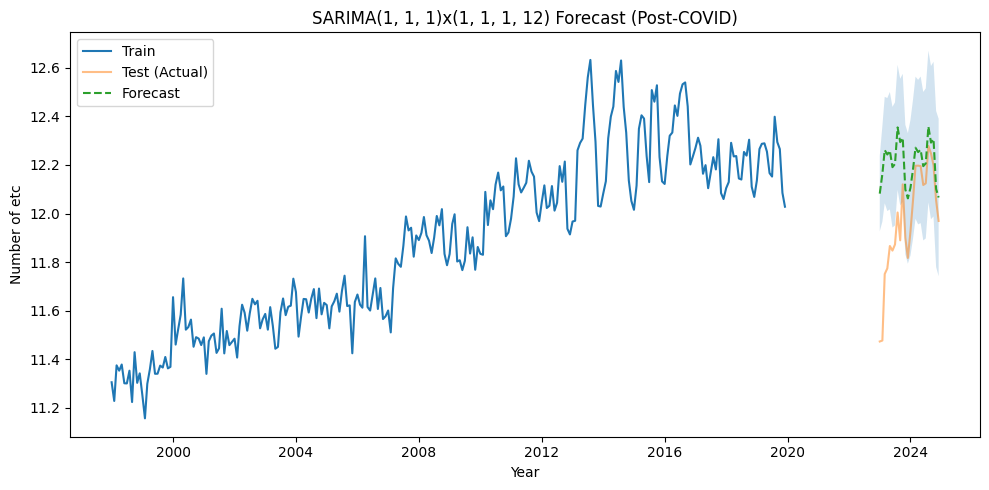

MAE  : 0.24
RMSE : 0.30
SMAPE : 2.00%


In [ ]:
# ----------------------------
# 3. SARIMAX 모델 학습
# ----------------------------
order = (1, 1, 1)
seasonal_order = (1, 1, 1, 12)

best_model = SARIMAX(
    train_etc_clean,
    order=order,
    seasonal_order=seasonal_order,
    exog=train_exog_clean,
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = best_model.fit()
print(results.summary())

# ----------------------------
# 4. 예측
# ----------------------------
forecast = results.get_forecast(steps=len(test_etc), exog=test_exog)
pred_mean = forecast.predicted_mean
pred_ci = forecast.conf_int()


pred_mean.index = test_etc.index
pred_ci.index = test_etc.index

# ----------------------------
# 5. 코로나 이후 구간만 선택
# ----------------------------
covid_end = '2022-12-01'
forecast_index = test_edu[test_etc.index > covid_end].index

y_true = test_etc.loc[forecast_index]
y_pred = pred_mean.loc[forecast_index]
pred_ci = pred_ci.loc[forecast_index]

# ----------------------------
# 6. 시각화
# ----------------------------
plt.figure(figsize=(10, 5))
plt.plot(train_etc_clean.index, train_etc_clean, label='Train')
plt.plot(test_etc.index, test_etc, label='Test (Actual)', alpha=0.5)
plt.plot(pred_mean.index, pred_mean, label='Forecast', linestyle='--')

plt.fill_between(
    pred_ci.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    alpha=0.2
)

plt.title(f"SARIMA{order}x{seasonal_order} Forecast (Post-COVID)")
plt.xlabel("Year")
plt.ylabel("Number of etc")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------
# 7. 평가 지표 계산
# ----------------------------
mae = mean_absolute_error(y_true, y_pred)
rmse = mean_squared_error(y_true, y_pred) ** 0.5

y_true_np = y_true.to_numpy()
y_pred_np = y_pred.to_numpy()
epsilon = 1e-10

smape = 100 * np.mean(2 * np.abs(y_true_np - y_pred_np) / (np.abs(y_true_np) + np.abs(y_pred_np) + epsilon))

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"SMAPE : {smape:.2f}%")